In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/semantic_ablation/source_snapshot.csv').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})


# 01 · Context engineering fundamentals

## tl;dr
SAP RPT receives labeled invoice rows inside each inference request. XGBoost fits model weights on the same rows. This notebook shows the frozen data and checks the split used by later experiments.

## Context & methods
The source is `data/semantic_ablation/source_snapshot.csv`. Rows 1–896 form the selection pool, 897–1024 validation, and 1025–1152 the final holdout. Context examples must come from eligible earlier rows. Global selection chooses one subset for all queries; query-specific selection chooses a subset per invoice without reading its target.

In [2]:
data = pd.read_csv(ROOT / 'data/semantic_ablation/source_snapshot.csv')
selection, validation, holdout = data.iloc[:896], data.iloc[896:1024], data.iloc[1024:]
assert data.invoice_id.is_unique and not data.isna().any().any()
assert not set(selection.invoice_id) & set(holdout.invoice_id)
display(pd.DataFrame({'split': ['selection', 'validation', 'holdout'], 'rows': [len(selection), len(validation), len(holdout)], 'late_positives': [selection.paid_late.sum(), validation.paid_late.sum(), holdout.paid_late.sum()], 'fraud_positives': [selection.is_fraud.sum(), validation.is_fraud.sum(), holdout.is_fraud.sum()]}))

,split,rows,late_positives,fraud_positives
0,selection,896,388,44
1,validation,128,62,9
2,holdout,128,51,8


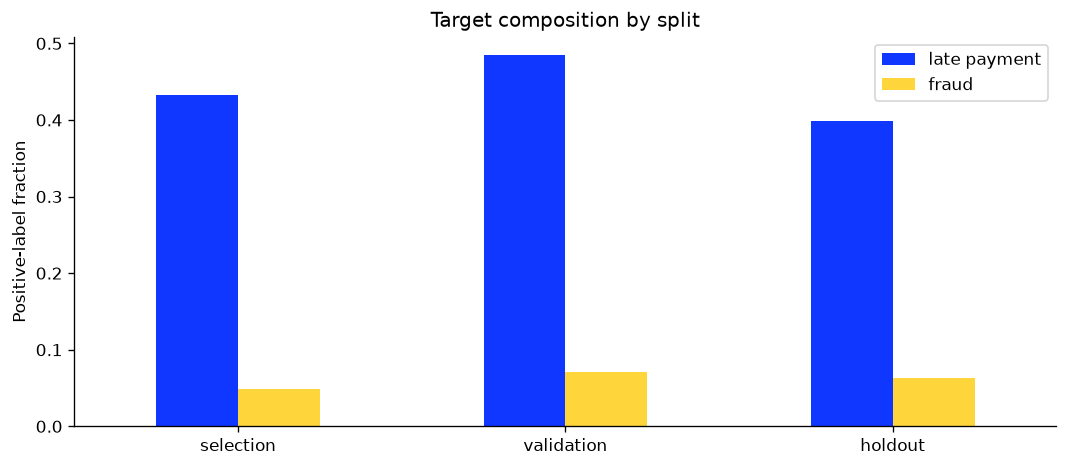

In [3]:
composition = pd.DataFrame({'late payment': [selection.paid_late.mean(), validation.paid_late.mean(), holdout.paid_late.mean()], 'fraud': [selection.is_fraud.mean(), validation.is_fraud.mean(), holdout.is_fraud.mean()]}, index=['selection','validation','holdout'])
ax = composition.plot.bar(rot=0, color=['#0F37FF','#FFD53C']); ax.set_ylabel('Positive-label fraction'); ax.set_title('Target composition by split'); plt.tight_layout(); plt.show()

## Takeaways
Fraud is rare in the frozen snapshot. Precision, recall, F1 and false positives are essential to interpret changes; accuracy alone would hide missed fraud.